In [2]:
%matplotlib inline
import os
!pip install gdown

** P1: ** Generación de Ejemplos Adversarios

En este código utilizaremos el primer y uno de los métodos de ataque adversario más populares, el **Fast Gradient Sign Attack (FGSM)** descrito por Goodfellow et al. en [**Explaining and Harnessing Adversarial Examples**](https://arxiv.org/abs/1412.6572), para engañar a un clasificador de MNIST. El ataque FGSM es un ataque de *caja blanca* (*white-box*) cuyo objetivo es provocar una *clasificación errónea* de las entradas.

La idea es sencilla: en lugar de utilizar los gradientes retropropagados para ajustar los pesos de la red con el objetivo de minimizar la función de pérdida, el ataque **modifica los datos de entrada para maximizar la pérdida** utilizando esos mismos gradientes.

![](https://pytorch.org/tutorials/_static/img/fgsm_panda_image.png)

La imagen original, $\mathbf{x}$ es  correctamente clasificada como un  "panda", $y$ es la clase verdadera $\mathbf{x}$,
$\mathbf{\theta}$ representa los parámetros del modelo, y
$J(\mathbf{\theta}, \mathbf{x}, y)$ es el error de pérdida utilizado para entrenar.

El atacante retropropaga el gradiente para calcular $\nabla_{x} J(\mathbf{\theta}, \mathbf{x}, y)$. Luego
ajusta los datos de entrada multiplicando el gradiente por un factor de escala ($\epsilon$ or $0.007$ en la figura) maximizando la pérdida. La imagen modificada resultante, $x'$, luego será *mal clasificada * por el modelo como un "gibbon" cuando claramente para nuestra vista sigue siendo un  "panda".


In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt



El código tiene esencialmente 3 entradas:

-   `epsilons` - Lista de epsilons, siendo importante mantener el valor 0 para obtener la performance original del modelo.
-   `pretrained_model` - utilizaremos un modelo pre-entrenado, cargándolo directamente.
-    `test_set` - conjunto de imágenes de test

In [4]:
epsilons = [0, .05, .1, .15, .2, .25, .3]
pretrained_model = "data/lenet_mnist_model.pth"
# Set random seed for reproducibility
torch.manual_seed(42)

In [5]:
# Crear el directorio 'data' en caso de que no exista:
if not os.path.exists('data'):
    os.makedirs('data')

El modelo

Descarga el modelo "lenet_mnist_model.pth" desde el CV y guárdalo en el directorio "data".


In [6]:
# LeNet Model definition
# Si bien cargamos el modelo (los pesos), debemos darle
# la estructura original de la red utilizada para entrenar
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        # Corrected convolutional layers to match the pretrained model (LeNet-5 like)
        self.conv1 = nn.Conv2d(1, 10, 5, 1) # From 32 out_channels, 3x3 kernel to 10 out_channels, 5x5 kernel
        self.conv2 = nn.Conv2d(10, 20, 5, 1) # From 32->64 in/out_channels, 3x3 kernel to 10->20 in/out_channels, 5x5 kernel
        self.dropout1 = nn.Dropout(0.25)
        self.dropout2 = nn.Dropout(0.5)
        # Corrected fully connected layers input/output sizes
        self.fc1 = nn.Linear(320, 50) # From 9216 input to 320, from 128 output to 50
        self.fc2 = nn.Linear(50, 10) # From 128 input to 50

    def forward(self, x):
        x = self.conv1(x)
        x = F.relu(x)
        x = F.max_pool2d(x, 2) # Added first pooling layer after conv1 as in typical LeNet-5
        x = self.conv2(x)
        x = F.relu(x)
        x = F.max_pool2d(x, 2) # Second pooling layer (was already there, but now after the corrected conv2)
        x = self.dropout1(x)
        x = torch.flatten(x, 1) # This will now result in 20*4*4 = 320 features
        x = self.fc1(x)
        x = F.relu(x)
        x = self.dropout2(x)
        x = self.fc2(x)
        output = F.log_softmax(x, dim=1)
        return output

# MNIST Test dataset and dataloader declaration
test_loader = torch.utils.data.DataLoader(
    datasets.MNIST('../data', train=False, download=True, transform=transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize((0.1307,), (0.3081,)), #normalizacion que aplica al dataset
            ])),
        batch_size=1, shuffle=True)

# We want to be able to train our model on an `accelerator <https://pytorch.org/docs/stable/torch.html#accelerators>`__
# such as CUDA, MPS, MTIA, or XPU. If the current accelerator is available, we will use it. Otherwise, we use the CPU.
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

# Initialize the network
model = Net().to(device)

# Load the pretrained model
model.load_state_dict(torch.load(pretrained_model, map_location=device, weights_only=True))

# Set the model in evaluation mode. In this case this is for the Dropout layers
model.eval()

Using cpu device


Net(
  (conv1): Conv2d(1, 10, kernel_size=(5, 5), stride=(1, 1))
  (conv2): Conv2d(10, 20, kernel_size=(5, 5), stride=(1, 1))
  (dropout1): Dropout(p=0.25, inplace=False)
  (dropout2): Dropout(p=0.5, inplace=False)
  (fc1): Linear(in_features=320, out_features=50, bias=True)
  (fc2): Linear(in_features=50, out_features=10, bias=True)
)

EL ataque FGSM
==============

La función`fgsm_attack` toma la imagen original ($x$), *epsilon* que indica la perturbación a utilizar a nivel píxel ($\epsilon$), y  *data\_grad* que es el gradeinte del error respecto a la imagen de entrada
($\nabla_{x} J(\mathbf{\theta}, \mathbf{x}, y)$). Se crea entonces la imagen modificada como:

$$perturbed\_image = image + epsilon*sign(data\_grad) = x + \epsilon * sign(\nabla_{x} J(\mathbf{\theta}, \mathbf{x}, y))$$

Se utiliza una normalización (clip) para mantener el rango correcto de valores de la imagen.


El modelo recibe input del tensor normalizado, FGSM calcula sobre el input oringial de la imagen [0,1]  por lo tanto antes de pasarlo al generador del ataque FGSM, tenemos que coger input, denorm, generate attack, normalize.

In [ ]:
# FGSM attack code
def fgsm_attack(image, epsilon, data_grad):
    # Collect the element-wise sign of the data gradient
    sign_data_grad = data_grad.sign()
    # Create the perturbed image by adjusting each pixel of the input image
    perturbed_image = image + epsilon*sign_data_grad
    # Adding clipping to maintain [0,1] range
    perturbed_image = torch.clamp(perturbed_image, 0, 1)
    # Return the perturbed image
    return perturbed_image

# restores the tensors to their original scale
def denorm(batch, mean=[0.1307], std=[0.3081]):
    """
    Convert a batch of tensors to their original scale.

    Args:
        batch (torch.Tensor): Batch of normalized tensors.
        mean (torch.Tensor or list): Mean used for normalization.
        std (torch.Tensor or list): Standard deviation used for normalization.

    Returns:
        torch.Tensor: batch of tensors without normalization applied to them.
    """
    if isinstance(mean, list):
        mean = torch.tensor(mean).to(device)
    if isinstance(std, list):
        std = torch.tensor(std).to(device)

    return batch * std.view(1, -1, 1, 1) + mean.view(1, -1, 1, 1)

Test
====

Cada llamada a la función de test realiza una ejecución sobre todas las imágenes de test para cada valor de  *epsilon*, calculando el error obtenido.

In [11]:
# for i, (data, target) in enumerate(test_loader):
#     print(f"Batch {i}:")
#     print(data.shape)
#     print(target.shape)
#     if i >= 5:
#         break

Batch 0:
torch.Size([1, 1, 28, 28])
torch.Size([1])
Batch 1:
torch.Size([1, 1, 28, 28])
torch.Size([1])
Batch 2:
torch.Size([1, 1, 28, 28])
torch.Size([1])
Batch 3:
torch.Size([1, 1, 28, 28])
torch.Size([1])
Batch 4:
torch.Size([1, 1, 28, 28])
torch.Size([1])
Batch 5:
torch.Size([1, 1, 28, 28])
torch.Size([1])


In [6]:
def test( model, device, test_loader, epsilon ):

    # Accuracy counter
    correct = 0
    adv_examples = []

    # Loop over all examples in test set
    for data, target in test_loader:

        # Send the data and label to the device
        data, target = data.to(device), target.to(device)

        # Set requires_grad attribute of tensor. Important for Attack
        data.requires_grad = True

        # Forward pass the data through the model
        output = model(data)
        init_pred = output.max(1, keepdim=True)[1] # get the index of the max log-probability

        # If the initial prediction is wrong, don't bother attacking, just move on
        if init_pred.item() != target.item():
            continue

        # Calculate the loss
        loss = F.nll_loss(output, target)

        # Zero all existing gradients
        model.zero_grad()

        # Calculate gradients of model in backward pass
        loss.backward()

        # Collect ``datagrad``
        data_grad = data.grad.data

        # Restore the data to its original scale
        data_denorm = denorm(data)

        # Call FGSM Attack
        perturbed_data = fgsm_attack(data_denorm, epsilon, data_grad)

        # Reapply normalization
        perturbed_data_normalized = transforms.Normalize((0.1307,), (0.3081,))(perturbed_data)

        # Re-classify the perturbed image
        output = model(perturbed_data_normalized)

        # Check for success
        final_pred = output.max(1, keepdim=True)[1] # get the index of the max log-probability
        if final_pred.item() == target.item():
            correct += 1
            # Special case for saving 0 epsilon examples
            if epsilon == 0 and len(adv_examples) < 5:
                adv_ex = perturbed_data.squeeze().detach().cpu().numpy()
                adv_examples.append( (init_pred.item(), final_pred.item(), adv_ex) )
        else:
            # Save some adv examples for visualization later
            if len(adv_examples) < 5:
                adv_ex = perturbed_data.squeeze().detach().cpu().numpy()
                adv_examples.append( (init_pred.item(), final_pred.item(), adv_ex) )

    # Calculate final accuracy for this epsilon
    final_acc = correct/float(len(test_loader))
    print(f"Epsilon: {epsilon}\tTest Accuracy = {correct} / {len(test_loader)} = {final_acc}")

    # Return the accuracy and an adversarial example
    return final_acc, adv_examples

In [12]:
from tqdm import tqdm
accuracies = []
examples = []

# Run test for each epsilon
for eps in tqdm(epsilons):
    acc, ex = test(model, device, test_loader, eps)
    accuracies.append(acc)
    examples.append(ex)

 14%|█▍        | 1/7 [00:29<02:59, 29.89s/it]

Epsilon: 0	Test Accuracy = 9838 / 10000 = 0.9838


 29%|██▊       | 2/7 [00:59<02:29, 29.98s/it]

Epsilon: 0.05	Test Accuracy = 9480 / 10000 = 0.948


 43%|████▎     | 3/7 [01:29<01:59, 29.78s/it]

Epsilon: 0.1	Test Accuracy = 8635 / 10000 = 0.8635


... (4 outputs left out)

 86%|████████▌ | 6/7 [02:59<00:29, 29.93s/it]

Epsilon: 0.25	Test Accuracy = 2683 / 10000 = 0.2683


100%|██████████| 7/7 [03:29<00:00, 29.97s/it]

Epsilon: 0.3	Test Accuracy = 1305 / 10000 = 0.1305


Resultados
==========

El código genera una gráfica de Accuracy en función de los valores de Epsilon.

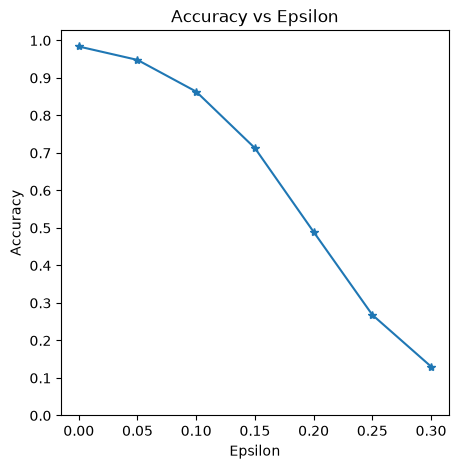

In [13]:
plt.figure(figsize=(5,5))
plt.plot(epsilons, accuracies, "*-")
plt.yticks(np.arange(0, 1.1, step=0.1))
plt.xticks(np.arange(0, .35, step=0.05))
plt.title("Accuracy vs Epsilon")
plt.xlabel("Epsilon")
plt.ylabel("Accuracy")
plt.show()

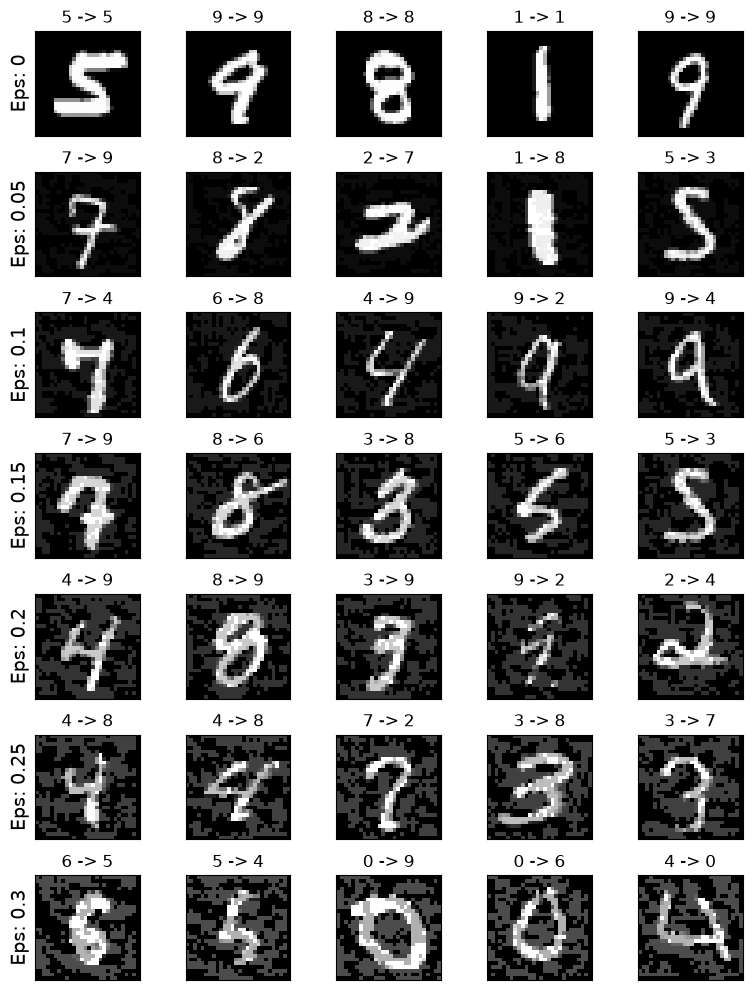

In [14]:
# Plot several examples of adversarial samples at each epsilon
cnt = 0
plt.figure(figsize=(8,10))
for i in range(len(epsilons)):
    for j in range(len(examples[i])):
        cnt += 1
        plt.subplot(len(epsilons),len(examples[0]),cnt)
        plt.xticks([], [])
        plt.yticks([], [])
        if j == 0:
            plt.ylabel(f"Eps: {epsilons[i]}", fontsize=14)
        orig,adv,ex = examples[i][j]
        plt.title(f"{orig} -> {adv}")
        plt.imshow(ex, cmap="gray")
plt.tight_layout()
plt.show()